# Practice Building Agentic Team with Langgraph

### llm 

In [1]:
from dotenv import load_dotenv
import os
load_dotenv()

from langchain_aws import ChatBedrockConverse

llm = ChatBedrockConverse(model="global.openai.gpt-6-luna",region_name="eu-west-1")
response = llm.invoke("hi")

### tools

In [2]:
import yfinance as yf

def get_stock_price(ticker: str) -> float:
    """Latest closing price for a ticker, e.g. 'AAPL'."""
    return round(float(yf.Ticker(ticker).history(period="1d")["Close"].iloc[-1]), 2)

### build workflow

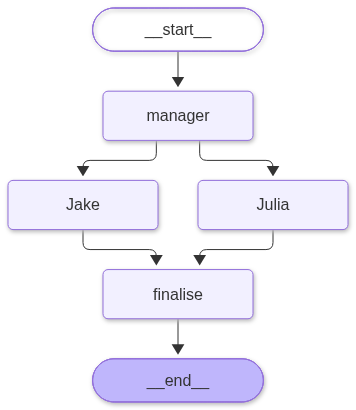

In [3]:
from typing import TypedDict, NotRequired
from langgraph.graph import StateGraph, START, END
from langchain.agents import create_agent
from langchain_core.tools import tool
from IPython.display import Image, display

julia_agent = create_agent(
    model=llm,
    tools=[tool(get_stock_price)],
    system_prompt="You are Julia, a market analyst. Get prices only with get_stock_price. Never invent figures; separate facts from interpretation.",
)

class State(TypedDict):
    task: str
    manager_note: NotRequired[str]
    Jake: NotRequired[str]
    Julia: NotRequired[str]
    final_answer: NotRequired[str]

def show(title, text):                      # print one section with separators
    print(f"\n{'=' * 60}\n{title}\n{'=' * 60}\n{text.strip()}")
    return text

def manager(s: State):
    return {"manager_note": show("MANAGER", llm.invoke(
        f"You manage a financial analysis team. Task: {s['task']}\n"
        "Split it into two independent parts. Jake: company and business findings and risks (no invented news or figures). "
        "Julia: get the stock price with get_stock_price and analyse it. State each person's responsibilities.").text)}

def Jake(s: State):
    return {"Jake": show("JAKE", llm.invoke(
        f"You are Jake, a business research analyst. Task: {s['task']}\nManager's instructions: {s['manager_note']}\n"
        "Do ONLY Jake's part, concisely. Do not invent recent events or figures.").text)}

def Julia(s: State):
    out = julia_agent.invoke({"messages": [("user",
        f"Task: {s['task']}\nManager's instructions: {s['manager_note']}\nDo ONLY Julia's part. Use get_stock_price.")]})
    return {"Julia": show("JULIA", out["messages"][-1].text)}

def finalise(s: State):
    return {"final_answer": show("FINAL REPORT", llm.invoke(
        f"Task: {s['task']}\nJake's findings: {s['Jake']}\nJulia's market analysis: {s['Julia']}\n"
        "Write a professional briefing: executive summary, latest stock price, key findings, risks, conclusion. "
        "Invent nothing; flag what could not be verified.").text)}

g = StateGraph(State)
for name, fn in [("manager", manager), ("Jake", Jake), ("Julia", Julia), ("finalise", finalise)]:
    g.add_node(name, fn)
g.add_edge(START, "manager")
g.add_edge("manager", "Jake")
g.add_edge("manager", "Julia")
g.add_edge(["Jake", "Julia"], "finalise")      # waits for both
g.add_edge("finalise", END)
app = g.compile()

display(Image(app.get_graph().draw_mermaid_png()))

### run 

In [4]:
response_ = app.invoke(
    {"task": "Write a briefing about Alibaba's latest stock price and key findings."})

print(response_)


MANAGER
# Alibaba briefing

## Part 1 — Jake: Company, business findings and risks

**Responsibility:** Summarize Alibaba’s businesses and material risks, without relying on unverified current news or figures.

**Business findings**
- Alibaba is a diversified technology and commerce group. Its businesses include China-focused e-commerce, international commerce, cloud computing, logistics and local services.
- Its e-commerce platforms connect merchants and consumers; its cloud business provides computing and related technology services.
- Performance can vary substantially across these businesses. Group-level results therefore depend on both the health of its core commerce operations and the growth and profitability of its other segments.

**Key risks**
- **Competition:** Alibaba faces competition in e-commerce, cloud computing and other digital services, which can pressure growth, margins and customer retention.
- **Consumer and economic conditions:** Weaker spending or changes in mer